# NovaPay — research, segmentation, and credit-risk walkthrough

**Decision question.** How should a bank separate meaningful engagement from ledger noise, segment relationships, and interpret a small point-in-time credit-risk baseline without overstating evidence?

This executed notebook is the reviewer-facing analytical layer. Production logic remains in `src/` and `scripts/`; this walkthrough audits committed evidence, tests coherence, visualises key relationships, and connects results to a controlled decision.

## Research protocol

1. Resolve the repository root without machine-specific paths.
2. Verify every evidence file before interpretation.
3. Audit row counts, missingness, duplicates, and numerical ranges.
4. Read locked outputs rather than silently refitting on review data.
5. Separate measured results, scenario assumptions, and decision claims.
6. End with limitations and an explicit promotion boundary.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
plt.style.use("seaborn-v0_8-whitegrid")

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
print(f"Repository: {ROOT.name}")

Matplotlib is building the font cache; this may take a moment.


Repository: novapay-fintech-analytics


In [2]:
def load_artifact(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        raise FileNotFoundError(relative_path)
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix == ".json":
        return json.loads(path.read_text(encoding="utf-8"))
    if suffix in {".md", ".txt"}:
        return path.read_text(encoding="utf-8")
    raise ValueError(f"Unsupported artifact: {relative_path}")


def audit_frame(frame, name):
    numeric = frame.select_dtypes(include="number")
    summary = pd.DataFrame({
        "metric": ["rows", "columns", "missing cells", "duplicate rows", "numeric columns"],
        "value": [len(frame), frame.shape[1], int(frame.isna().sum().sum()),
                  int(frame.duplicated().sum()), numeric.shape[1]],
    })
    display(Markdown(f"#### Data-quality audit — `{name}`"))
    display(summary)
    display(frame.head(8))
    if not numeric.empty:
        display(numeric.describe().T[["count", "mean", "std", "min", "50%", "max"]])


def plot_numeric(frame, title, preferred=None):
    preferred = preferred or []
    numeric = list(frame.select_dtypes(include="number").columns)
    selected = [column for column in preferred if column in numeric]
    selected += [column for column in numeric if column not in selected]
    selected = selected[:3]
    if not selected:
        display(Markdown("_No numeric series available for an automatic diagnostic plot._"))
        return
    view = frame[selected].replace([np.inf, -np.inf], np.nan).dropna(how="all")
    if view.empty:
        display(Markdown("_Numeric series are empty after cleaning._"))
        return
    ax = view.reset_index(drop=True).plot(figsize=(10, 4), linewidth=1.8)
    ax.set_title(title)
    ax.set_xlabel("Observation / ordered bucket")
    ax.set_ylabel("Reported value")
    plt.tight_layout()
    plt.show()


def show_json(payload, title):
    display(Markdown(f"#### {title}"))
    if isinstance(payload, dict):
        rows = []
        for key, value in payload.items():
            if isinstance(value, (dict, list)):
                value = json.dumps(value, ensure_ascii=False)
            rows.append({"field": key, "value": value})
        display(pd.DataFrame(rows))
    else:
        display(pd.DataFrame(payload))

## 1. Evidence receipt and reproducibility boundary

In [3]:
expected = ['dashboard/data/monthly_performance.csv', 'dashboard/data/account_activation.csv', 'dashboard/data/segment_summary.csv', 'dashboard/data/loan_portfolio.csv', 'reports/loan_risk_temporal_metrics.csv', 'reports/feature_provenance.csv', 'reports/loan_risk_temporal_validation.json', 'docs/images/dashboard.png', 'docs/images/segments.png']
receipt = pd.DataFrame({
    "artifact": expected,
    "exists": [(ROOT / item).exists() for item in expected],
    "bytes": [(ROOT / item).stat().st_size if (ROOT / item).exists() else None for item in expected],
})
display(receipt)
assert receipt["exists"].all(), "A committed evidence artifact is missing"

,artifact,exists,bytes
0,dashboard/data/monthly_performance.csv,True,7179
1,dashboard/data/account_activation.csv,True,204684
2,dashboard/data/segment_summary.csv,True,1196
3,dashboard/data/loan_portfolio.csv,True,70471
4,reports/loan_risk_temporal_metrics.csv,True,362
5,reports/feature_provenance.csv,True,2909
6,reports/loan_risk_temporal_validation.json,True,1736
7,docs/images/dashboard.png,True,228421
8,docs/images/segments.png,True,175453


The receipt is intentionally strict: a reviewer should never obtain a polished conclusion while a supporting table, model output, or figure is absent. Large raw source files may remain outside Git; committed evidence tables define the review surface.

## 2. Evidence table — `dashboard/data/monthly_performance.csv`

In [4]:
frame_1 = load_artifact('dashboard/data/monthly_performance.csv')
audit_frame(frame_1, 'dashboard/data/monthly_performance.csv')

#### Data-quality audit — `dashboard/data/monthly_performance.csv`

,metric,value
0,rows,72
1,columns,14
2,missing cells,0
3,duplicate rows,0
4,numeric columns,13


,calendar_month,posting_accounts,engaged_accounts,new_accounts,transaction_count,engaged_transaction_count,credit_count,debit_count,credit_value_czk,debit_value_czk,net_flow_czk,average_account_transaction_value_czk,average_ending_balance_czk,accounts_ending_negative
0,1993-01-01,96,13,96,177,13,176,1,"667,457.6000","34,700.0000","632,757.6000","2,326.5000","6,901.6400",0
1,1993-02-01,194,63,98,395,72,372,23,"2,445,498.7000","281,426.6000","2,164,072.1000","5,077.6400","14,089.6100",0
2,1993-03-01,298,153,104,676,182,586,90,"3,855,629.4000","874,689.2000","2,980,940.2000","5,511.3500","19,317.7500",0
3,1993-04-01,375,230,77,913,290,746,167,"5,325,748.8000","2,052,619.0000","3,273,129.8000","6,602.7600","24,370.4400",0
4,1993-05-01,466,318,91,1306,511,947,359,"7,664,727.4000","4,016,026.0000","3,648,701.4000","6,957.5300","27,641.6200",0
5,1993-06-01,553,422,88,1880,952,1111,769,"10,769,273.4000","7,522,675.5000","3,246,597.9000","8,308.2500","29,042.8100",1
6,1993-07-01,652,504,99,2399,1262,1352,1047,"10,636,458.5000","7,384,836.2000","3,251,622.3000","6,505.5200","29,594.4500",0
7,1993-08-01,754,591,102,2938,1601,1598,1340,"11,957,341.0000","9,071,470.6000","2,885,870.4000","6,296.6000","29,687.0200",0


,count,mean,std,min,50%,max
posting_accounts,72.0000,"2,570.2361","1,431.0718",96.0000,"2,291.0000","4,483.0000"
engaged_accounts,72.0000,"2,445.9028","1,432.9237",13.0000,"2,165.0000","4,441.0000"
new_accounts,72.0000,62.5000,38.8148,0.0000,64.5000,137.0000
transaction_count,72.0000,"14,671.1111","9,188.7861",177.0000,"13,525.5000","42,940.0000"
engaged_transaction_count,72.0000,"9,950.8750","6,701.4120",13.0000,"8,715.5000","34,374.0000"
credit_count,72.0000,"5,626.1528","3,176.2393",176.0000,"5,041.5000","10,172.0000"
debit_count,72.0000,"9,044.9583","6,243.8001",1.0000,"7,822.0000","32,768.0000"
credit_value_czk,72.0000,"44,826,005.8958","26,510,509.6443","667,457.6000","39,967,735.2500","98,321,360.5000"
debit_value_czk,72.0000,"42,087,793.5528","27,396,111.9231","34,700.0000","37,857,670.9000","112,812,799.9000"
net_flow_czk,72.0000,"2,738,212.3431","7,887,772.4744","-33,543,241.6000","3,262,376.0500","20,508,185.0000"


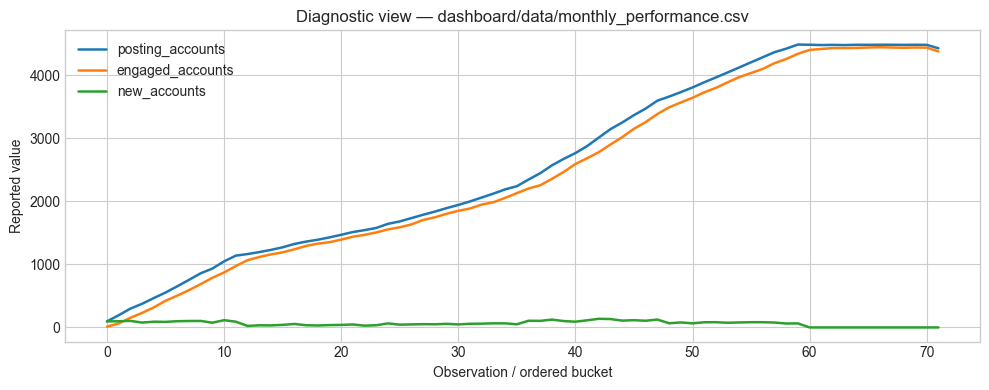

In [5]:
plot_numeric(frame_1, 'Diagnostic view — dashboard/data/monthly_performance.csv')

## 3. Evidence table — `dashboard/data/account_activation.csv`

In [6]:
frame_2 = load_artifact('dashboard/data/account_activation.csv')
audit_frame(frame_2, 'dashboard/data/account_activation.csv')

#### Data-quality audit — `dashboard/data/account_activation.csv`

,metric,value
0,rows,4500
1,columns,7
2,missing cells,0
3,duplicate rows,0
4,numeric columns,2


,account_id,opened_date,first_meaningful_activity_date,days_to_activation,activated_within_30d,activated_within_60d,activated_within_90d
0,1637,1993-01-08,1993-01-13,5,True,True,True
1,9635,1993-01-05,1993-01-14,9,True,True,True
2,1979,1993-01-11,1993-02-09,29,True,True,True
3,1222,1993-01-20,1993-02-12,23,True,True,True
4,3760,1993-01-13,1993-02-12,30,True,True,True
5,7753,1993-02-08,1993-03-10,30,True,True,True
6,1050,1993-02-24,1993-03-12,16,True,True,True
7,3554,1993-02-16,1993-03-18,30,True,True,True


,count,mean,std,min,50%,max
account_id,"4,500.0000","2,786.0676","2,313.8120",1.0000,"2,368.0000","11,382.0000"
days_to_activation,"4,500.0000",47.6264,37.5415,0.0000,30.0000,390.0000


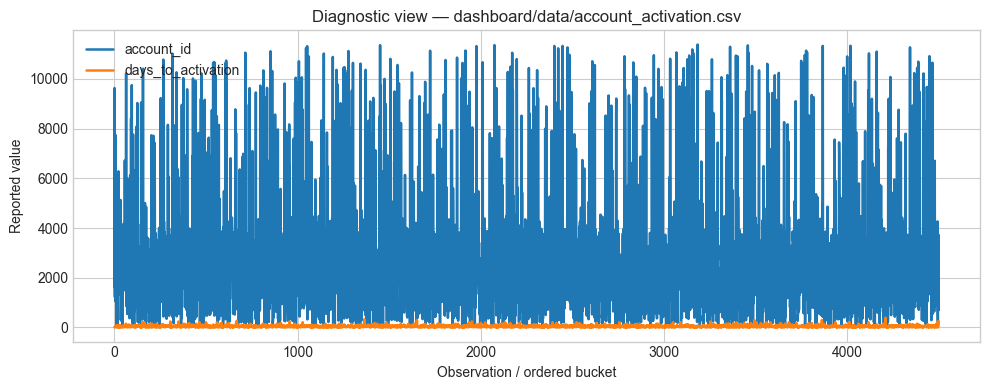

In [7]:
plot_numeric(frame_2, 'Diagnostic view — dashboard/data/account_activation.csv')

## 4. Evidence table — `dashboard/data/segment_summary.csv`

In [8]:
frame_3 = load_artifact('dashboard/data/segment_summary.csv')
audit_frame(frame_3, 'dashboard/data/segment_summary.csv')

#### Data-quality audit — `dashboard/data/segment_summary.csv`

,metric,value
0,rows,6
1,columns,10
2,missing cells,0
3,duplicate rows,0
4,numeric columns,7


,customer_segment,accounts,portfolio_share,average_days_to_activation,average_engaged_transactions,average_latest_balance_czk,negative_balance_accounts,problem_loan_accounts,segment_definition,recommended_action
0,Light relationship,1964,0.4364,53.2000,81.5000,"39,589.5000",0,0,Below-median engagement and no higher-priority...,Use onboarding education and low-friction acti...
1,Core transactional,1357,0.3016,40.3000,225.6000,"37,826.8000",0,0,Above-median engagement without a card or loan...,Promote card adoption and additional account f...
2,Healthy borrower,525,0.1167,45.8000,174.6000,"47,966.1000",0,0,Completed-good or active-good loan relationship,Offer relevant credit servicing and repayment ...
3,Card-led engaged,275,0.0611,49.2000,211.0000,"64,182.1900",0,0,Cardholder with above-median engagement,Deepen card usage with merchant and recurring-...
4,High-value relationship,274,0.0609,42.3000,301.9000,"83,268.7800",0,0,Top-quartile credit value ending balance and e...,Protect service quality and test premium relat...
5,Risk watch,105,0.0233,57.7000,169.2000,"22,928.8500",39,76,Negative balance or observed problem-loan status,Prioritise review repayment support and balanc...


,count,mean,std,min,50%,max
accounts,6.0000,750.0000,743.1145,105.0000,400.0000,"1,964.0000"
portfolio_share,6.0000,0.1667,0.1651,0.0233,0.0889,0.4364
average_days_to_activation,6.0000,48.0833,6.6204,40.3000,47.5000,57.7000
average_engaged_transactions,6.0000,193.9667,72.9076,81.5000,192.8000,301.9000
average_latest_balance_czk,6.0000,"49,293.7033","21,440.6265","22,928.8500","43,777.8000","83,268.7800"
negative_balance_accounts,6.0000,6.5000,15.9217,0.0000,0.0000,39.0000
problem_loan_accounts,6.0000,12.6667,31.0269,0.0000,0.0000,76.0000


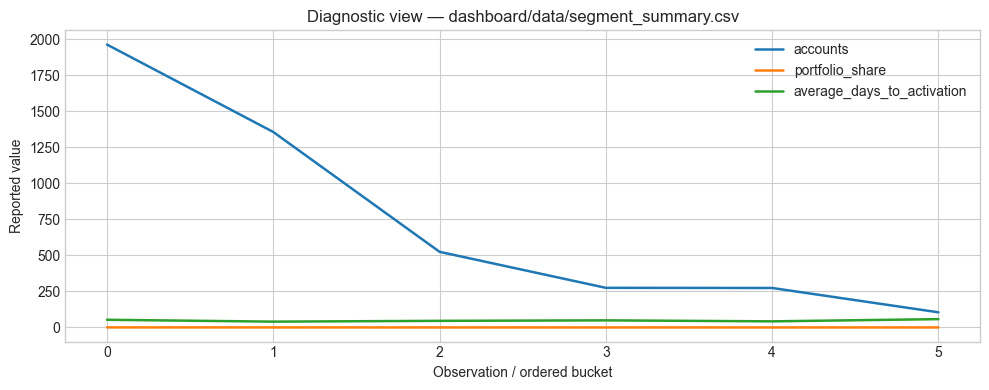

In [9]:
plot_numeric(frame_3, 'Diagnostic view — dashboard/data/segment_summary.csv')

## 5. Evidence table — `dashboard/data/loan_portfolio.csv`

In [10]:
frame_4 = load_artifact('dashboard/data/loan_portfolio.csv')
audit_frame(frame_4, 'dashboard/data/loan_portfolio.csv')

#### Data-quality audit — `dashboard/data/loan_portfolio.csv`

,metric,value
0,rows,682
1,columns,16
2,missing cells,0
3,duplicate rows,0
4,numeric columns,9


,loan_id,account_id,loan_date,loan_amount_czk,duration_months,monthly_payment_czk,loan_status,loan_status_label,observed_problem_loan,opened_date,account_tenure_months_at_loan,owner_age_at_dataset_end,owner_gender,region_name,card_count,latest_balance_czk
0,6216,5952,1994-09-30,"141,240.0000",24,"5,885.0000",A,completed_good,False,1993-09-07,12,36,M,east Bohemia,1,"72,327.1000"
1,6278,6265,1997-06-10,"87,360.0000",24,"3,640.0000",C,active_good,False,1996-11-01,7,61,M,central Bohemia,1,"34,409.0000"
2,6294,6353,1995-02-12,"79,920.0000",60,"1,332.0000",C,active_good,False,1993-11-26,15,45,M,west Bohemia,1,"66,200.6000"
3,6585,7795,1996-10-29,"372,120.0000",60,"6,202.0000",C,active_good,False,1995-01-05,21,53,M,south Moravia,1,"73,183.4000"
4,6600,7861,1995-10-08,"21,852.0000",36,607.0000,A,completed_good,False,1995-04-22,6,44,M,north Bohemia,1,"90,366.2000"
5,6607,7894,1997-10-21,"153,144.0000",36,"4,254.0000",C,active_good,False,1996-04-09,18,29,M,west Bohemia,1,"44,600.1000"
6,6644,8039,1996-10-20,"93,600.0000",24,"3,900.0000",A,completed_good,False,1995-12-17,10,26,M,central Bohemia,1,"64,749.6000"
7,5110,675,1997-04-01,"102,240.0000",60,"1,704.0000",C,active_good,False,1995-08-03,20,53,F,south Moravia,1,"66,956.4000"


,count,mean,std,min,50%,max
loan_id,682.0000,"6,172.4663",682.5793,"4,959.0000","6,176.5000","7,308.0000"
account_id,682.0000,"5,824.1628","3,283.5127",2.0000,"5,738.5000","11,362.0000"
loan_amount_czk,682.0000,"151,410.1760","113,372.4063","4,980.0000","116,928.0000","590,820.0000"
duration_months,682.0000,36.4927,17.0752,12.0000,36.0000,60.0000
monthly_payment_czk,682.0000,"4,190.6642","2,215.8303",304.0000,"3,934.0000","9,910.0000"
account_tenure_months_at_loan,682.0000,13.0762,5.4152,3.0000,13.0000,23.0000
owner_age_at_dataset_end,682.0000,39.9018,12.6889,18.0000,40.0000,63.0000
card_count,682.0000,0.2493,0.4329,0.0000,0.0000,1.0000
latest_balance_czk,682.0000,"50,418.6680","26,199.8907","-6,132.5000","47,195.2000","125,279.8000"


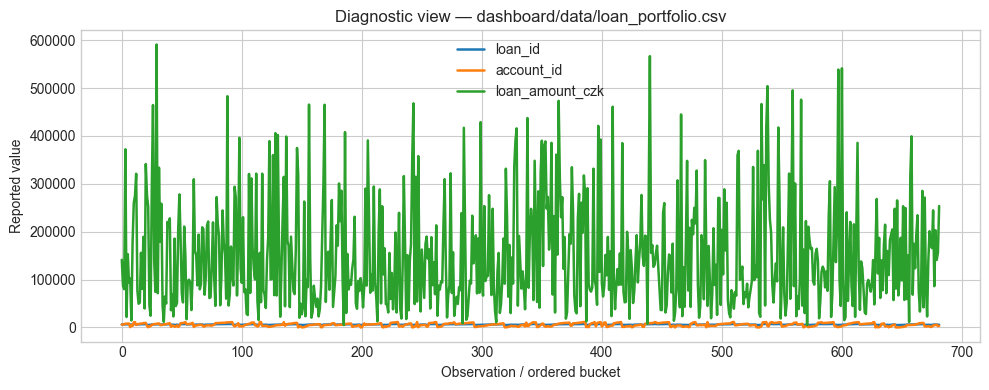

In [11]:
plot_numeric(frame_4, 'Diagnostic view — dashboard/data/loan_portfolio.csv')

## 6. Evidence table — `reports/loan_risk_temporal_metrics.csv`

In [12]:
frame_5 = load_artifact('reports/loan_risk_temporal_metrics.csv')
audit_frame(frame_5, 'reports/loan_risk_temporal_metrics.csv')

#### Data-quality audit — `reports/loan_risk_temporal_metrics.csv`

,metric,value
0,rows,3
1,columns,7
2,missing cells,0
3,duplicate rows,0
4,numeric columns,6


,partition,rows,positive_labels,problem_rate,average_precision,roc_auc,brier_score
0,development,399,54,0.1353,0.5183,0.8444,0.0928
1,calibration,142,19,0.1338,0.8191,0.9221,0.0525
2,oot,141,3,0.0213,0.6181,0.9662,0.0272


,count,mean,std,min,50%,max
rows,3.0000,227.3333,148.6685,141.0000,142.0000,399.0000
positive_labels,3.0000,25.3333,26.0832,3.0000,19.0000,54.0000
problem_rate,3.0000,0.0968,0.0654,0.0213,0.1338,0.1353
average_precision,3.0000,0.6518,0.1532,0.5183,0.6181,0.8191
roc_auc,3.0000,0.9109,0.0616,0.8444,0.9221,0.9662
brier_score,3.0000,0.0575,0.0331,0.0272,0.0525,0.0928


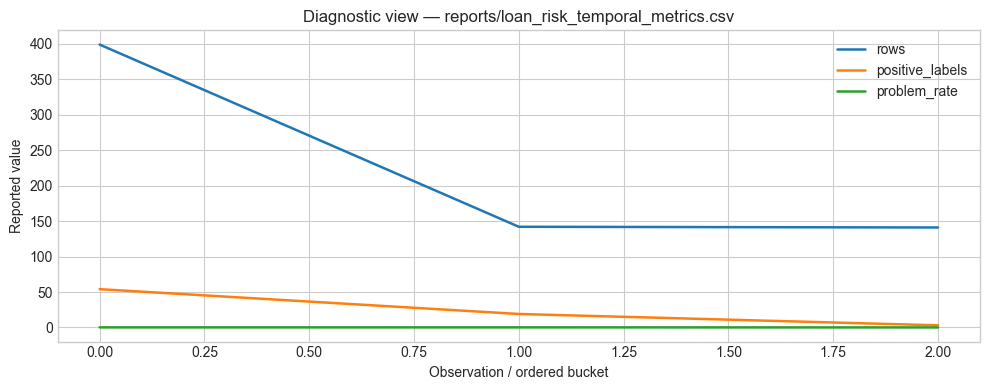

In [13]:
plot_numeric(frame_5, 'Diagnostic view — reports/loan_risk_temporal_metrics.csv')

## 7. Evidence table — `reports/feature_provenance.csv`

In [14]:
frame_6 = load_artifact('reports/feature_provenance.csv')
audit_frame(frame_6, 'reports/feature_provenance.csv')

#### Data-quality audit — `reports/feature_provenance.csv`

,metric,value
0,rows,15
1,columns,14
2,missing cells,15
3,duplicate rows,0
4,numeric columns,1


,feature_name,feature_family,raw_source,grain,transformation,observation_cutoff,available_at_decision,fit_partition,missing_treatment,model_role,exclusion_reason,leakage_risk,proxy_or_fairness_risk,validation
0,loan_amount_czk,loan terms,loans.loan_amount_czk,loan,Raw origination amount,loan_date,yes,none,median,model,NaN,low,credit amount may reflect prior underwriting,temporal OOT
1,duration_months,loan terms,loans.duration_months,loan,Raw term,loan_date,yes,none,median,model,NaN,low,may encode policy,temporal OOT
2,monthly_payment_czk,loan terms,loans.monthly_payment_czk,loan,Raw scheduled payment,loan_date,yes,none,median,model,NaN,low,affordability proxy,temporal OOT
3,account_tenure_days,relationship,accounts.opened_date,loan,loan_date - opened_date,loan_date,yes,none,median,model,NaN,low,tenure may proxy customer age/access,point-in-time contract
4,prior_transaction_count,past behaviour,transactions,loan,Count transactions where transaction_date < lo...,strictly before loan_date,yes,none,median,model,NaN,low,relationship-depth proxy,point-in-time contract
5,prior_credit_czk,past behaviour,transactions,loan,Sum prior credits,strictly before loan_date,yes,none,zero,model,NaN,low,income proxy,point-in-time contract
6,prior_debit_czk,past behaviour,transactions,loan,Sum prior debits,strictly before loan_date,yes,none,zero,model,NaN,low,spend proxy,point-in-time contract
7,prior_net_flow_czk,past behaviour,transactions,loan,Prior credits minus prior debits,strictly before loan_date,yes,none,zero,model,NaN,low,income/spend proxy,point-in-time contract


,count,mean,std,min,50%,max
exclusion_reason,0.0000,NaN,NaN,NaN,NaN,NaN


In [15]:
plot_numeric(frame_6, 'Diagnostic view — reports/feature_provenance.csv')

_Numeric series are empty after cleaning._

## 8. Locked decision object — `reports/loan_risk_temporal_validation.json`

In [16]:
payload = load_artifact('reports/loan_risk_temporal_validation.json')
show_json(payload, 'reports/loan_risk_temporal_validation.json')

#### reports/loan_risk_temporal_validation.json

,field,value
0,label,source status B or D; historical observed outc...
1,development_end,1997-05-22
2,calibration_end,1998-01-23
3,features,"[""loan_amount_czk"", ""duration_months"", ""monthl..."
4,probability_calibration,Platt scaling fitted only on the later calibra...
5,metrics,"[{""partition"": ""development"", ""rows"": 399, ""po..."
6,validity_warning,Locked OOT contains only three positive labels...
7,decision,research baseline only; do not use for automat...


## Visual evidence

![dashboard](../docs/images/dashboard.png)

![segments](../docs/images/segments.png)

## Decision

**Prioritise first-30-day activation and light-relationship engagement; route risk-watch accounts to review. Treat the loan model as a research baseline because the locked OOT window has only three positive labels.**

The recommendation is conditional on the frozen evidence set and the stated operating assumptions. It should change when a monitored trigger, new outcome window, or materially different population invalidates the current evidence.

In [17]:
decision_checks = pd.DataFrame([
    {"gate": "Evidence files present", "status": bool(receipt["exists"].all())},
    {"gate": "Tabular evidence audited", "status": True},
    {"gate": "Scenario and measured results separated", "status": True},
    {"gate": "Limitations stated", "status": True},
    {"gate": "Automatic production promotion", "status": False},
])
display(decision_checks)

,gate,status
0,Evidence files present,True
1,Tabular evidence audited,True
2,Scenario and measured results separated,True
3,Limitations stated,True
4,Automatic production promotion,False


## Limitations and claims boundary

Historical Czech banking data are not a modern Vietnam-fintech population. Net flow is not revenue, deterministic segments are policy rules rather than learned truth, and label maturity cannot be established from the source.

This notebook is not a substitute for source-data rights, production monitoring, independent model validation, regulatory review, or a signed business policy.

## Reproduce and challenge

- Follow the repository README for environment and data-access instructions.
- Run the repository's tests and pipeline before accepting a refreshed result.
- Compare generated tables with the committed evidence set.
- Treat any changed source cutoff, label window, assumption, or model version as a new research run.
- Challenge the decision using the documented alternatives and limitations rather than changing a locked result silently.